In [1]:
import numpy as np


def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF using the multiplicative updates in equations (14) and (18).

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative input matrix. Each column is one sample.
    n_components : int
        Number of basis vectors.
    W_init : array-like, shape (n_features, n_components), optional
        Initial nonnegative basis matrix.
    H_init : array-like, shape (n_components, n_samples), optional
        Initial nonnegative activation matrix.
    lambda_sparse : float
        Sparsity regularization coefficient, lambda >= 0.
    g : callable, optional
        Elementwise sparsity penalty. Default: g(h) = h.
    g_prime : callable, optional
        Elementwise derivative of g. Default: g'(h) = 1.
        If a custom g is provided, g_prime must also be provided.
    max_iter : int
        Maximum number of iterations.
    tol : float
        Relative objective-change tolerance for stopping.
    eps : float
        Small positive constant for numerical stability.
    random_state : int, optional
        Random seed for initialization.
    return_history : bool
        If True, also return objective values and their components.

    Returns
    -------
    W : ndarray, shape (n_features, n_components)
        L2-normalized basis matrix.
    H : ndarray, shape (n_components, n_samples)
        Activation matrix.
    history : list of dicts, optional
        Returned only when return_history=True.

    Notes
    -----
    The returned matrices satisfy the reconstruction convention
        V_hat = W @ H
    with L2-normalized columns of W.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")
    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")
    if not isinstance(n_components, (int, np.integer)) or n_components < 1:
        raise ValueError("n_components must be a positive integer.")
    if lambda_sparse < 0:
        raise ValueError("lambda_sparse must be nonnegative.")
    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")
    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")
    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    # Default: linear sparsity penalty, g(h) = h.
    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape
    rng = np.random.default_rng(random_state)

    # Initialize W.
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()
        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")
        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")
        W = np.maximum(W, eps)

    # Initialize H.
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()
        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")
        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")
        H = np.maximum(H, eps)

    def elementwise(func, X, name):
        """Evaluate a penalty or derivative elementwise."""
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def evaluate_objective(W_bar, H):
        """Objective: 0.5 * ||V - W_bar H||_F^2 + lambda * sum(g(H))."""
        R = W_bar @ H
        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")
        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)
        return reconstruction_loss + sparsity_loss, reconstruction_loss, sparsity_loss

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        # ---------------------------------------------------------
        # Steps 1-3:
        # Compute the gradient of each basis norm, normalize W,
        # and reconstruct V.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        # For the L2 norm: grad_W ||W_j||_2 = W_j / ||W_j||_2.
        grad_norm = W_bar

        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 4: update H using equation (14).
        #
        # H[j, i] <- H[j, i] *
        #   (W_bar[:, j]^T V[:, i]) /
        #   (W_bar[:, j]^T R[:, i] + lambda * g'(H[j, i]))
        # ---------------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")
        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        # ---------------------------------------------------------
        # Step 5: reconstruct using the updated activations.
        # ---------------------------------------------------------
        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 6: update the non-normalized W using equation (18).
        #
        # W_j <- W_j * numerator_j / denominator_j
        #
        # All components are updated simultaneously.
        # ---------------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        # Scalar sums over samples i, one value per component j.
        weighted_R_proj = np.sum(H * proj_R, axis=1)[None, :]
        weighted_V_proj = np.sum(H * proj_V, axis=1)[None, :]

        W_num = V @ H.T + grad_norm * weighted_R_proj
        W_den = R @ H.T + grad_norm * weighted_V_proj

        W *= np.maximum(W_num, 0.0) / np.maximum(W_den, eps)
        W = np.maximum(W, eps)

        # ---------------------------------------------------------
        # Evaluate convergence using the updated basis directions.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        loss, rec_loss, sparse_loss = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss) / max(abs(previous_loss), eps)
            )

        history.append({
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        })

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    # Return normalized bases, consistent with the reconstruction in step 3.
    W_final = W / np.maximum(np.linalg.norm(W, axis=0), eps)[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H

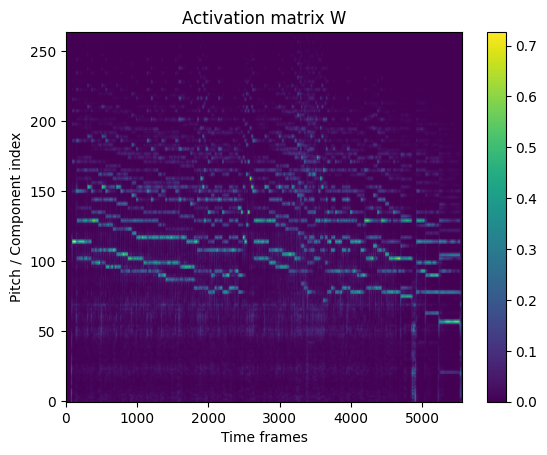

In [9]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
K = 3
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

(264, 88)


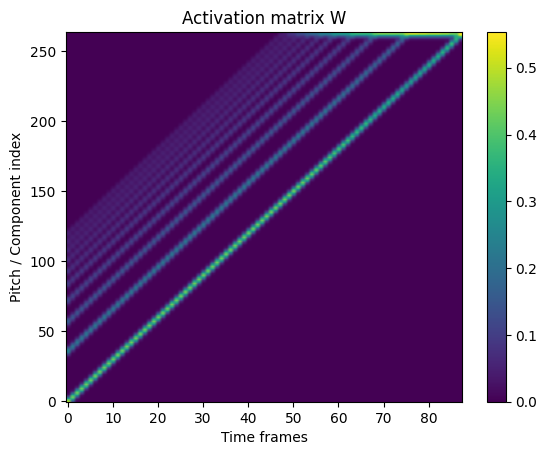

In [11]:
def build_W0(sr,
             bins_per_octave,
             n_bins,
             fmin,
             n_harmonics=10,
             decay=1.0,
             sigma=1.5,
             inharmonicity=0.0):

    # CQT frequency grid (MUST match your spectrogram)
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave
    )

    midi_notes = np.arange(21, 21 + 88)  # piano
    W0 = np.zeros((n_bins, len(midi_notes)))

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins)

        for h in range(1, n_harmonics + 1):
            # optional piano inharmonicity
            fh = h * f0 * np.sqrt(1 + inharmonicity * h**2)

            if fh >= sr / 2:
                break

            # nearest bin
            idx = np.argmin(np.abs(freqs - fh))

            # Gaussian spread
            k = np.arange(n_bins)
            peak = np.exp(-(k - idx)**2 / (2 * sigma**2))

            template += (1 / (h ** decay)) * peak

        # normalize (critical)
        template /= np.linalg.norm(template) + 1e-10

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn

W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
#Wn = build_noise_basis(88*K, 1)
#W_0 = np.concatenate([W_0, Wn], axis=1)

print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

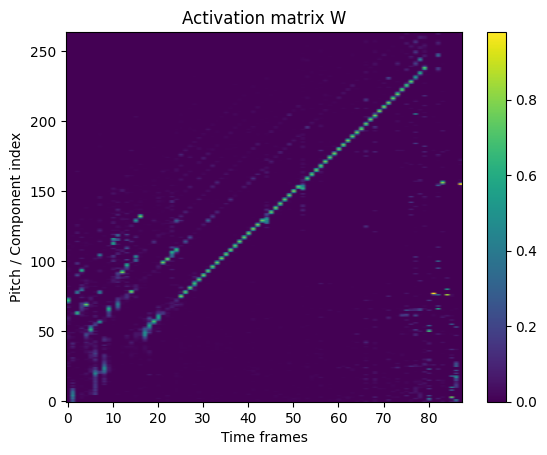

In [24]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [45]:
# V.shape = (n_frequency_bins, n_frames)
#H_0 = np.random((88,spectrogram.shape[1]))

W, H, history = sparse_nmf(
    spectrogram,
    W_init=W_0,
    n_components=88,
    lambda_sparse=1e-6,
    max_iter=500,
    tol=1e-5,
    random_state=42,
    return_history=True,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)
print("Reconstruction:", V_hat.shape)
print("Iterations:", len(history))
print("Final objective:", history[-1]["loss"])

W: (264, 88)
H: (88, 5562)
Reconstruction: (264, 5562)
Iterations: 500
Final objective: 21.909663871843627


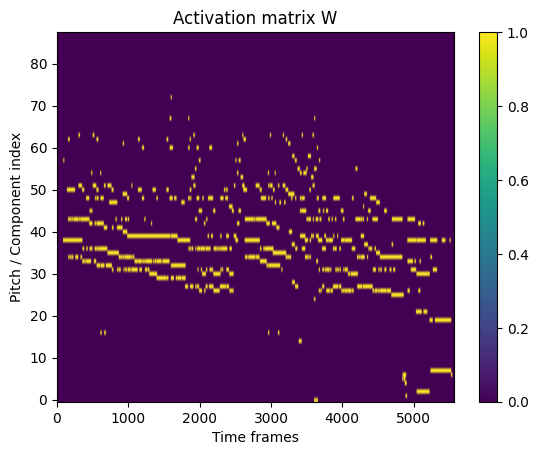

In [59]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -17, axis=0)[-17:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2)
t = H3.max() * 0.2
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [28]:
pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.5 MB/s eta 0:00:00


In [29]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

(88, 5513) (88, 5562)


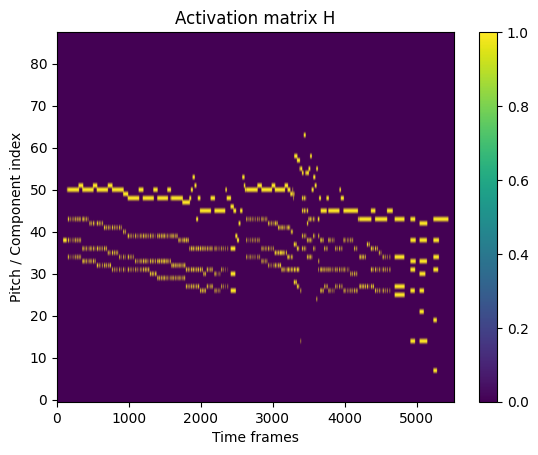

In [30]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = 1024 / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [31]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [58]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.6072106261859582, 0.43825610591189224, 0.5090812674002385)
